# Level 5 — Missing values

Before filling nulls, I want to know which fields are missing and whether a replacement would change the meaning of the data.

In [1]:
from pathlib import Path
import pandas as pd

# Works if I open Jupyter from the repo root or from notebooks/
data_path = Path("data/sales_raw.csv")
if not data_path.exists():
    data_path = Path("../data/sales_raw.csv")

df = pd.read_csv(data_path)
df.head(3)

,line_id,order_id,order_date,customer_id,city,category,product,quantity,unit_price_pkr,discount_pct,revenue_pkr,payment_method,order_status,channel,delivery_days
0,LN-00001,ORD-2025-25001,2025-05-13,C-1023,Lahore,Office,Whiteboard,4,6000,10%,21600.0,Card,Delivered,Store,10.0
1,LN-00002,ORD-2025-25001,2025-08-19,C-1134,Islamabad,Home,Wall Clock,5,3100,15%,13175.0,Cash,Delivered,Store,8.0
2,LN-00003,ORD-2025-25002,2025-09-10,C-1052,Rawalpindi,NaN,Desk Lamp,3,2592,0%,7776.0,Bank Transfer,Delivered,Online,6.0


### Find and rank missing columns

In [2]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(2)
}).sort_values("pct", ascending=False)
missing[missing["count"] > 0]

,count,pct
delivery_days,117,20.71
discount_pct,33,5.84
payment_method,24,4.25
category,18,3.19
revenue_pkr,15,2.65
city,13,2.30
customer_id,9,1.59


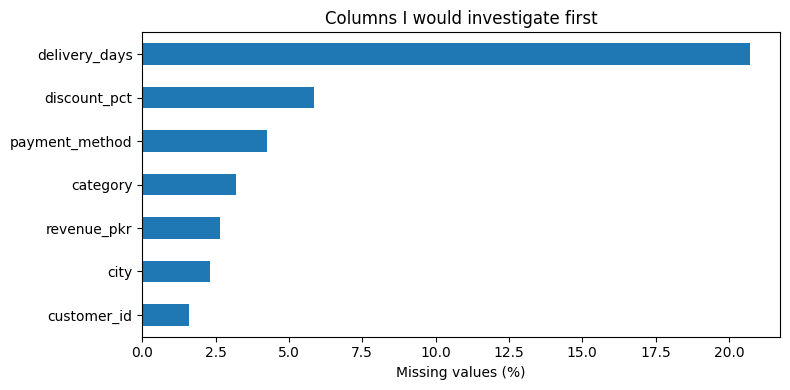

In [3]:
import matplotlib.pyplot as plt

missing["pct"].loc[lambda s: s > 0].sort_values().plot.barh(figsize=(8, 4))
plt.xlabel("Missing values (%)")
plt.title("Columns I would investigate first")
plt.tight_layout()
plt.show()

### Are missing delivery days related to status?
This is a first check. It does not prove MCAR, MAR or MNAR.

In [4]:
pd.crosstab(
    df["order_status"],
    df["delivery_days"].isna(),
    normalize="index"
).round(3)

delivery_days,False,True
order_status,,
Cancelled,0.000,1.000
Delivered,0.953,0.047
Pending,0.018,0.982
Returned,0.000,1.000


### Make safe working copies
Missing payment methods can be labelled "Not recorded". I would not use zero for missing revenue.

In [5]:
work = df.copy()
work["payment_method"] = work["payment_method"].fillna("Not recorded")
work["city_missing"] = work["city"].isna()
work[["payment_method", "city", "city_missing"]].head(8)

,payment_method,city,city_missing
0,Card,Lahore,False
1,Cash,Islamabad,False
2,Bank Transfer,Rawalpindi,False
3,Cash,Islamabad,False
4,Card,Lahore,False
5,Wallet,Faisalabad,False
6,Cash,Karachi,False
7,Cash,Karachi,False


### Example: median imputation for an analysis-only copy
This should only be done if it fits the question. We keep a flag so we know which values were filled.

In [6]:
work["delivery_imputed"] = work["delivery_days"].isna()

# Only fill delivered orders; otherwise "not delivered" is not a missing delivery time
delivered = work["order_status"].eq("Delivered")
median_days = work.loc[delivered, "delivery_days"].median()
work.loc[delivered, "delivery_days"] = work.loc[delivered, "delivery_days"].fillna(median_days)
print("Median delivery days:", median_days)
print("Remaining missing delivery values:", work["delivery_days"].isna().sum())

Median delivery days: 6.0
Remaining missing delivery values: 95


### Compare available revenue with the missing portion

In [7]:
print("Revenue missing:", work["revenue_pkr"].isna().sum())
print("Revenue available total:", round(work["revenue_pkr"].sum(), 2))
print("Missing revenue by status:")
print(pd.crosstab(work["order_status"], work["revenue_pkr"].isna()))

Revenue missing: 15
Revenue available total: 3284302.2
Missing revenue by status:
revenue_pkr   False  True 
order_status              
Cancelled        28      1
Delivered       456     13
Pending          55      0
Returned         11      1


**My note:** `fillna(0)` would silently treat unknown sales as zero. That could affect business KPIs, so I would validate those records from the source first.